## 5. Passenger Power

In [19]:
# on charge pandas pour les tableaux et matplotlib pour les graphiques
import pandas as pd
import matplotlib.pyplot as plt

# on lit le fichier des CFF et les colonnes sont séparé par ;
df = pd.read_csv("data/passagierfrequenz.csv", sep=";")

In [20]:
# les 5 grandes gares qu'on va comparer
gares = ["Zürich HB", "Bern", "Lausanne", "Genève", "Luzern"]

# on garde seulement l'année 2025
df_2025 = df[df["Jahr_Annee_Anno"] == 2025]

# on garde seulement les lignes des 5 gares de la liste
cinq = df_2025[df_2025["Bahnhof_Gare_Stazione"].isin(gares)]

# on garde 3 colonnes : le nom, le numéro UIC et les montées + descentes par jour
cinq = cinq[["Bahnhof_Gare_Stazione", "UIC", "DTV_TJM_TGM"]].copy()

# on transforme 8501008.0 en "8501008" pour pouvoir le comparer avec les horaires
cinq["didok"] = cinq["UIC"].astype(int).astype(str)
cinq

,Bahnhof_Gare_Stazione,UIC,DTV_TJM_TGM,didok
105,Bern,8507000.0,177000.0,8507000
4021,Lausanne,8501120.0,97500.0,8501120
4038,Luzern,8505000.0,108800.0,8505000
4914,Genève,8501008.0,83100.0,8501008
5712,Zürich HB,8503000.0,449800.0,8503000


In [21]:
# le dossier où on a dézippé les horaires
dossier = "data/gtfs_fp2026_20261118/"

# on lit la liste de tous les arrêts de Suisse, tout en texte (dtype=str)
stops = pd.read_csv(dossier + "stops.txt", dtype=str)

# on garde les arrêts dont le didok est celui d'une de nos 5 gares
arrets = stops[stops["didok"].isin(cinq["didok"])]
arrets = arrets[["stop_id", "stop_name", "platform_code", "didok"]]
arrets

,stop_id,stop_name,platform_code,didok
3042,ch:1:sloid:1008,Genève,NaN,8501008
3043,ch:1:sloid:1008:1:1,Genève,1,8501008
3044,ch:1:sloid:1008:2:2,Genève,2,8501008
3045,ch:1:sloid:1008:2:3,Genève,3,8501008
3046,ch:1:sloid:1008:3:4,Genève,4,8501008
...,...,...,...,...
71975,Parentch:1:sloid:1008,Genève,NaN,8501008
76639,Parentch:1:sloid:1120,Lausanne,NaN,8501120
81681,Parentch:1:sloid:3000,Zürich HB,NaN,8503000
83695,Parentch:1:sloid:5000,Luzern,NaN,8505000


In [22]:
# les arrêts de Genève seulement
arrets[arrets["didok"] == "8501008"]

,stop_id,stop_name,platform_code,didok
3042,ch:1:sloid:1008,Genève,NaN,8501008
3043,ch:1:sloid:1008:1:1,Genève,1,8501008
3044,ch:1:sloid:1008:2:2,Genève,2,8501008
3045,ch:1:sloid:1008:2:3,Genève,3,8501008
3046,ch:1:sloid:1008:3:4,Genève,4,8501008
3047,ch:1:sloid:1008:3:5,Genève,10,8501008
3048,ch:1:sloid:1008:3:6,Genève,5,8501008
3049,ch:1:sloid:1008:4:7,Genève,6,8501008
3050,ch:1:sloid:1008:4:8,Genève,7,8501008
3051,ch:1:sloid:1008_gen:ch:1:sloid:1008:2:2_pf:2E-H,Genève,2E-H,8501008


In [23]:
# stop_times.txt est énorme : on le lit par morceaux de 2 millions de lignes,
# et seulement 2 colonnes sur 7
lecteur = pd.read_csv(dossier + "stop_times.txt", usecols=["trip_id", "stop_id"], dtype=str, chunksize=2_000_000)

# une liste vide pour ranger les petits tas qu'on garde
morceaux = []

# pour chaque morceau, on garde les lignes qui passent par un de nos 128 arrêts
for morceau in lecteur:
    morceaux.append(morceau[morceau["stop_id"].isin(arrets["stop_id"])])

# on colle tous les petits tas en un seul tableau
passages = pd.concat(morceaux)
passages

,trip_id,stop_id
414070,.ojp-91-10-A.1.TA.1.j26,ch:1:sloid:3088:0:82204
414076,.ojp-91-10-A.1.TA.10.j26,ch:1:sloid:3088:0:82204
414162,.ojp-91-10-A.1.TA.11.j26,ch:1:sloid:3088:0:82204
414248,.ojp-91-10-A.1.TA.12.j26,ch:1:sloid:3088:0:82204
414334,.ojp-91-10-A.1.TA.13.j26,ch:1:sloid:3088:0:82204
...,...,...
35418848,.ojp-92-K11-A.1.TA.95.j26,ch:1:sloid:1008
35418850,.ojp-92-K11-A.1.TA.96.j26,ch:1:sloid:1008
35418852,.ojp-92-K11-A.1.TA.97.j26,ch:1:sloid:1008
35418854,.ojp-92-K11-A.1.TA.98.j26,ch:1:sloid:1008


In [24]:
# quel est le numéro (agency_id) de la compagnie RBS ?
agences = pd.read_csv(dossier + "agency.txt", dtype=str)
agences[agences["agency_name"].str.contains("Bern-Solothurn")][["agency_id", "agency_name"]]

,agency_id,agency_name
44,88,Regionalverkehr Bern-Solothurn
220,7246,Regionalverkehr Bern-Solothurn Ersatzverkehr


In [25]:
# on lit la liste des lignes de transport (routes) : chacune a un type (train, bus, tram...)
routes = pd.read_csv(dossier + "routes.txt", dtype=str)

# deux questions, chacune donne une colonne de True/False
# est-ce un train ? (types 100 à 117)
est_train = routes["route_type"].astype(int).between(100, 117)
# est-ce que ce n'est PAS le RBS (88) ? les CFF ne comptent pas ses voyageurs à Bern ("Sans RBS")
pas_rbs = routes["agency_id"] != "88"

# on garde le route_id des lignes qui répondent True aux deux
lignes_train = routes[est_train & pas_rbs]["route_id"]
len(lignes_train)

925

In [26]:
# le jour qu'on choisit : mercredi 25 novembre 2026
jour = 20261125

# calendar.txt : les horaires normaux de chaque service
cal = pd.read_csv(dossier + "calendar.txt", dtype=str)

# trois questions, chacune donne une colonne de True/False
mercredi = cal["wednesday"] == "1"
commence_avant = cal["start_date"].astype(int) <= jour
finit_apres = cal["end_date"].astype(int) >= jour

# on garde les services qui répondent True aux trois questions
actifs = cal[mercredi & commence_avant & finit_apres]["service_id"]
len(actifs)

40996

In [27]:
# calendar_dates.txt est gros : on le lit par morceaux et on garde seulement notre jour
caldat = pd.read_csv(dossier + "calendar_dates.txt", dtype=str, chunksize=2_000_000)
# (= [] vide la boîte morceaux avant de la réutiliser)
morceaux = []
for morceau in caldat:
    morceaux.append(morceau[morceau["date"] == str(jour)])
ce_jour = pd.concat(morceaux)

# type 1 = ajouté ce jour-là, type 2 = supprimé ce jour-là
ajoutes = ce_jour[ce_jour["exception_type"] == "1"]["service_id"]
retires = ce_jour[ce_jour["exception_type"] == "2"]["service_id"]

# on met ensemble les actifs et les ajoutés, puis on enlève les supprimés
services = pd.concat([actifs, ajoutes])
services = services[~services.isin(retires)]
len(ajoutes), len(retires), len(services)

(71, 34233, 6834)

In [28]:
# trips.txt : pour chaque trajet, sa ligne (route_id) et son calendrier (service_id)
trips = pd.read_csv(dossier + "trips.txt", usecols=["route_id", "service_id", "trip_id"], dtype=str)

# deux questions, chacune donne une colonne de True/False
est_un_train = trips["route_id"].isin(lignes_train)
roule_ce_jour = trips["service_id"].isin(services)

# on garde les trajets qui répondent True aux deux, et on sort leur trip_id
trains_du_jour = trips[est_un_train & roule_ce_jour]["trip_id"]

# dans passages, on garde seulement les passages de ces trajets-là
passages_trains = passages[passages["trip_id"].isin(trains_du_jour)]
len(trips), len(trains_du_jour), len(passages_trains)

(2615528, 19270, 4978)

In [29]:
# une liste vide pour ranger le nombre de trains de chaque gare
trains = []

# pour chaque gare (son numéro didok), on compte ses arrêts de trains le 25.11
for numero in cinq["didok"]:
    # les stop_id de cette gare (toutes ses voies)
    ids = arrets[arrets["didok"] == numero]["stop_id"]
    # combien de passages de trains tombent sur un de ces stop_id
    trains.append(passages_trains["stop_id"].isin(ids).sum())

# on ajoute la liste comme nouvelle colonne du petit tableau cinq
cinq["trains"] = trains
cinq

,Bahnhof_Gare_Stazione,UIC,DTV_TJM_TGM,didok,trains
105,Bern,8507000.0,177000.0,8507000,1043
4021,Lausanne,8501120.0,97500.0,8501120,644
4038,Luzern,8505000.0,108800.0,8505000,815
4914,Genève,8501008.0,83100.0,8501008,541
5712,Zürich HB,8503000.0,449800.0,8503000,1935


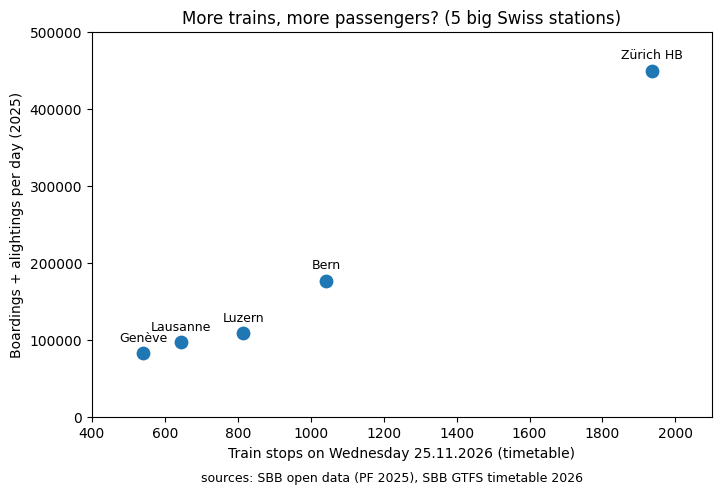

In [31]:
# une feuille de dessin (largeur 8, hauteur 5)
plt.figure(figsize=(8, 5))

# un point par gare : x = arrêts de trains le 25.11, y = montées + descentes par jour
plt.scatter(cinq["trains"], cinq["DTV_TJM_TGM"], s=80, color="tab:blue")

# on écrit le nom de chaque gare juste au-dessus de son point
noms = cinq["Bahnhof_Gare_Stazione"].tolist()
x = cinq["trains"].tolist()
y = cinq["DTV_TJM_TGM"].tolist()
for k in range(len(noms)):
    plt.text(x[k], y[k] + 15000, noms[k], fontsize=9, ha="center")

# l'axe des voyageurs commence à 0 pour montrer les vraies proportions
plt.ylim(0, 500000)
plt.xlim(400, 2100)

plt.title("More trains, more passengers? (5 big Swiss stations)")
plt.xlabel("Train stops on Wednesday 25.11.2026 (timetable)")
plt.ylabel("Boardings + alightings per day (2025)")
plt.figtext(0.5, -0.02, "sources: SBB open data (PF 2025), SBB GTFS timetable 2026", ha="center", fontsize=9)
plt.show()

In [32]:
# la corrélation : un chiffre entre -1 et +1 qui dit si trains et voyageurs montent ensemble
r = cinq["trains"].corr(cinq["DTV_TJM_TGM"])
print(f"corrélation entre trains et voyageurs : {r:.2f}")

corrélation entre trains et voyageurs : 0.99


In [33]:
# combien de montées + descentes par arrêt de train, dans chaque gare
cinq["par_train"] = (cinq["DTV_TJM_TGM"] / cinq["trains"]).round()
cinq[["Bahnhof_Gare_Stazione", "trains", "DTV_TJM_TGM", "par_train"]]

,Bahnhof_Gare_Stazione,trains,DTV_TJM_TGM,par_train
105,Bern,1043,177000.0,170.0
4021,Lausanne,644,97500.0,151.0
4038,Luzern,815,108800.0,133.0
4914,Genève,541,83100.0,154.0
5712,Zürich HB,1935,449800.0,232.0


### What we found

Zurich HB est une exception. Il y a énormément de montées et de descentes (449 800 par jour), beaucoup plus que dans les autres gares, peut-être parce que c'est le centre. Les autres gares, en Suisse romande et en Suisse alémanique, sont entre environ 80 000 et 180 000 montées et descentes par jour.

Zurich HB a à la fois beaucoup de trains et beaucoup de montées et descentes, les deux vont ensemble. La corrélation entre les trains et les voyageurs est de 0,99. Zurich a aussi 232 montées et descentes par arrêt de train, contre 133 à 170 ailleurs.

Lucerne a plus de trains que Lausanne et Genève, mais ses montées et descentes n'augmentent pas autant. Il ne décolle pas comme Berne, on aurait pu s'attendre à ce qu'il soit un peu plus haut.

### Limits

On a comparé seulement 5 gares, on n'a pas mis toutes les gares de Suisse. Du coup, le résultat est un peu fragile.

Les montées et descentes viennent du comptage de 2025, alors que les trains sont comptés sur une date de 2026 (le mercredi 25 novembre). La comparaison est donc seulement approximative.

Pour Berne, on a enlevé les trains RBS, parce que les CFF ne comptent pas les voyageurs du RBS (« Sans RBS »). Comme ça, on compare la même chose des deux côtés.

Pour Genève, les CFF ne comptent qu'en partie les voyageurs des trains qui viennent de l'étranger ou qui y vont, donc son chiffre est peut-être un peu trop bas. Lausanne n'a pas de remarque.